# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [1]:
# Import necessary libraries
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hides the info and warning messages

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
print("GPUs found:", gpus)

# Let TensorFlow take GPU memory gradually instead of grabbing all 6 GB at once
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

import random
import numpy as np
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # Hides INFO and WARNING logs from TensorFlow
import pandas as pd
import matplotlib.pyplot as plt
import pathlib

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

I0000 00:00:1793277582.106937   55020 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793277583.760877   55020 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


GPUs found: []


E0000 00:00:1793277585.558526   55020 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.


In [2]:
# TODO: Load and explore the RealWaste dataset
# - Dataset structure
# - Distribution of waste categories
# - Image characteristics (resolution, quality, background)

# Your code here


# --- STEP 1: Unzip RealWaste Dataset if not already extracted ---
import zipfile
from pathlib import Path

zip_path = Path('realwaste.zip')
extract_path = Path('RealWaste')

if zip_path.exists() and not extract_path.exists():
    print(f"Extracting '{zip_path}' into '{extract_path}'...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Extraction complete!")
elif extract_path.exists():
    print("Verified: 'RealWaste' directory already exists.")
else:
    print("Note: 'realwaste.zip' not found, proceeding with existing directories.")

# Load and explore the RealWaste dataset structure, categories, and image characteristics
import pathlib
import tensorflow as tf

# Define data directory
data_dir = pathlib.Path('RealWaste')

# 1. Dataset structure and category distribution
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
num_classes = len(class_names)
print(f"Dataset Structure Path: {data_dir.absolute()}")
print(f"Number of Waste Categories: {num_classes}")
print(f"Categories: {class_names}\n")

print("Distribution of Waste Categories:")
total_images = 0
for class_name in class_names:
    class_path = data_dir / class_name
    image_count = len(list(class_path.glob('*.*')))
    total_images += image_count
    print(f" - {class_name}: {image_count} images")

print(f"\nTotal Images across all categories: {total_images}")

# 2. Image characteristics inspection (resolution, quality, background)
sample_image_path = next(data_dir.glob('*/*.*'))
# Load a sample image using tf.keras.utils to inspect shape/resolution
sample_img = tf.keras.utils.load_img(sample_image_path)
sample_array = tf.keras.utils.img_to_array(sample_img)

print("\nImage Characteristics:")
print(f" - Sample Image File: {sample_image_path.name}")
print(f" - Original Resolution (Height, Width, Channels): {sample_array.shape}")
print(f" - Quality & Background: Images are captured in authentic landfill reception environments with varied unadulterated forms and background noise.")

Verified: 'RealWaste' directory already exists.
Dataset Structure Path: /home/komen/Documents/moringa_school_projects/Module_5_labs/dsc-ecosort-nn-summative-lab/RealWaste
Number of Waste Categories: 9
Categories: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']

Distribution of Waste Categories:
 - Cardboard: 461 images
 - Food Organics: 411 images
 - Glass: 420 images
 - Metal: 790 images
 - Miscellaneous Trash: 495 images
 - Paper: 500 images
 - Plastic: 921 images
 - Textile Trash: 318 images
 - Vegetation: 436 images

Total Images across all categories: 4752

Image Characteristics:
 - Sample Image File: Miscellaneous Trash_252.jpg
 - Original Resolution (Height, Width, Channels): (524, 524, 3)
 - Quality & Background: Images are captured in authentic landfill reception environments with varied unadulterated forms and background noise.


### 1.2 Explore Text Datasets

In [3]:
# TODO: Load and explore the waste description text data
# - Load waste_descriptions.csv
# - Analyze vocabulary and structure
# - Understand the distribution of categories

# Your code here
# Load and explore the waste description text data
import pandas as pd

# 1. Load waste_descriptions.csv
descriptions_df = pd.read_csv("waste_descriptions.csv")

print("--- Dataset Shape & Structure ---")
print(f"Total Rows and Columns: {descriptions_df.shape}")
print(f"Column Names: {descriptions_df.columns.tolist()}\n")

print("--- First 3 Rows Preview ---")
display(descriptions_df.head(3))

print("\n--- Missing Values Analysis ---")
print(descriptions_df.isnull().sum())

print("\n--- Distribution of Categories ---")
category_counts = descriptions_df['category'].value_counts()
print(category_counts)

# 2. Analyze vocabulary and text structure
# Calculate average description length (word count and character count)
descriptions_df["word_count"] = descriptions_df["description"].apply(lambda x: len(str(x).split()))
descriptions_df["char_count"] = descriptions_df["description"].apply(lambda x: len(str(x)))

print("\n--- Vocabulary & Text Structure Statistics ---")
print(f"Average Word Count per Description: {descriptions_df['word_count'].mean():.2f}")
print(f"Average Character Count per Description: {descriptions_df['char_count'].mean():.2f}")
print(f"Total Unique Vocabulary Words (approximate): {len(set(' '.join(descriptions_df['description'].astype(str)).lower().split()))}")

--- Dataset Shape & Structure ---
Total Rows and Columns: (5000, 5)
Column Names: ['description', 'category', 'disposal_instruction', 'common_confusion', 'material_composition']

--- First 3 Rows Preview ---


,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...



--- Missing Values Analysis ---
description                0
category                   0
disposal_instruction       0
common_confusion        2504
material_composition       0
dtype: int64

--- Distribution of Categories ---
category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                569
Glass                  551
Food Organics          518
Metal                  508
Paper                  506
Name: count, dtype: int64

--- Vocabulary & Text Structure Statistics ---
Average Word Count per Description: 4.85
Average Character Count per Description: 33.41
Total Unique Vocabulary Words (approximate): 305


In [4]:
# TODO: Load and explore the waste policy documents
# - Load waste_policy_documents.csv
# - Understand document organization and language

# Your code here
# Load and explore the waste policy documents
import json

# 1. Load waste_policy_documents.json
with open("waste_policy_documents.json", "r") as f:
    policy_documents = json.load(f)

print(f"--- Document Organization & Overview ---")
print(f"Total Policy Documents Loaded: {len(policy_documents)}")

# 2. Analyze structure and metadata
print(f"\nExample Document Keys / Fields: {list(policy_documents[0].keys())}")

# Collect unique policy types and jurisdictions
policy_types = [doc["policy_type"] for doc in policy_documents]
jurisdictions = set(doc["jurisdiction"] for doc in policy_documents)

print(f"Jurisdictions Covered: {jurisdictions}")
print(f"Total Unique Policy Types: {len(set(policy_types))}")

print("\n--- Language & Content Structure Sample ---")
# Display text style and organization of the first policy document
print(f"Policy Type: {policy_documents[0]['policy_type']}")
print(f"Effective Date: {policy_documents[0]['effective_date']}")
print(f"Categories Covered: {policy_documents[0]['categories_covered']}")
print("-" * 40)
print(policy_documents[0]["document_text"][:300] + "...\n[Content truncated for display]")

--- Document Organization & Overview ---
Total Policy Documents Loaded: 14

Example Document Keys / Fields: ['policy_id', 'policy_type', 'categories_covered', 'effective_date', 'document_text', 'jurisdiction']
Jurisdictions Covered: {'Metro City'}
Total Unique Policy Types: 14

--- Language & Content Structure Sample ---
Policy Type: Textile Trash Recycling Guidelines
Effective Date: 2023-11-04
Categories Covered: ['Textile Trash']
----------------------------------------
TEXTILE RECYCLING GUIDELINES

Acceptable Items:
- Clean clothing (all conditions)
- Towels, sheets, and linens
- Fabric scraps
- Curtains and cloth napkins
- Handbags and backpacks made of fabric
- Soft toys and stuffed animals

Non-Acceptable Items:
- Wet or moldy textiles
- Heavily soiled items
- ...
[Content truncated for display]


### 1.3 Create Data Pipelines

In [5]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path('RealWaste')

# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
# First, let's get the number of batches in the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752
Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [6]:
# TODO: Create a text preprocessing pipeline
# - Tokenization
# - Text cleaning
# - Split data into train and test
# - Create embeddings/features

# Your code here
# 1. Text Cleaning: We convert all characters to lowercase and strip out punctuation
#    and special characters so that words like "Plastic", "plastic", and "plastic!"
#    are treated as the exact same token by our machine learning model.
# 2. Train/Test Split: We partition our descriptions into 80% training data and
#    20% testing data using stratification (`stratify=y`) to ensure every waste
#    category maintains a balanced representation in both sets.
# 3. Tokenization & Feature Extraction (TF-IDF): We use Term Frequency-Inverse
#    Document Frequency (TF-IDF) to convert raw text into numerical feature vectors.
#    This measures how important a word is to a document relative to the entire corpus,
#    while automatically removing common English stop words (like "the", "and", "is").

import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Step A: Load the waste descriptions dataset
df_text = pd.read_csv('waste_descriptions.csv')

# Step B: Define text cleaning function
def clean_text(text):
    """Normalizes text: lowercase, removes special characters, fixes whitespace."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', '', text)  # Strip punctuation
    text = re.sub(r'\s+', ' ', text).strip()  # Clean excess spaces
    return text

# Apply cleaning function to create the processed text column
df_text['cleaned_description'] = df_text['description'].apply(clean_text)

# Step C: Split data into training and testing sets (80/20 ratio with stratification)
X = df_text['cleaned_description']
y = df_text['category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples count: {len(X_train)}")
print(f"Testing samples count: {len(X_test)}")

# Step D: Create TF-IDF vectorizer embeddings/features
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')

# Fit on training data and transform both train and test sets
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

print(f"TF-IDF Training Feature Matrix Shape: {X_train_vectorized.shape}")
print("Text preprocessing and embedding pipeline successfully executed!")

Training samples count: 4000
Testing samples count: 1000
TF-IDF Training Feature Matrix Shape: (4000, 298)
Text preprocessing and embedding pipeline successfully executed!


In [7]:
# TODO: Prepare documents for RAG
# - Document preprocessing
# - Create embeddings for retrieval

# Your code here

# 1. Document Preprocessing & Chunking: Policy documents in JSON format contain
#    rich multi-sentence rules. We parse these documents and split (chunk) them into
#    smaller, digestible text segments so our retrieval system can pinpoint exact
#    rules rather than searching through massive blocks of text.
# 2. Embedding Generation (TF-IDF / Vector Space): We convert these text chunks
#    into numerical vector representations using TF-IDF vectorization. This transforms
#    words into mathematical coordinates, allowing us to compute similarity scores
#    between a user's recycling question and our policy document database.

import json
from sklearn.feature_extraction.text import TfidfVectorizer

# Step A: Load the waste policy documents JSON file
with open('waste_policy_documents.json', 'r') as f:
    policy_data = json.load(f)

print(f"Loaded {len(policy_data)} raw policy documents from JSON.")

# Step B: Document Preprocessing & Chunking
# Extract document texts, policy types, and metadata into a list of chunks
policy_chunks = []
metadata_store = []

for doc in policy_data:
    doc_id = doc.get('policy_id', 'unknown')
    policy_type = doc.get('policy_type', 'General Policy')
    jurisdiction = doc.get('jurisdiction', 'Metro City')
    text = doc.get('document_text', '')

    # Simple sentence-based or paragraph-based chunking
    # Here we split large document texts into individual paragraphs/sentences for precise retrieval
    sentences = [s.strip() for s in text.split('.') if len(s.strip()) > 20]

    for i, sentence in enumerate(sentences):
        chunk_text = f"Policy: {policy_type} | Jurisdiction: {jurisdiction} | Rule: {sentence}."
        policy_chunks.append(chunk_text)
        metadata_store.append({
            'policy_id': doc_id,
            'policy_type': policy_type,
            'jurisdiction': jurisdiction,
            'chunk_index': i
        })

print(f"Generated {len(policy_chunks)} searchable policy chunks after preprocessing.")

# Step C: Create Embeddings for Retrieval using TF-IDF
rag_vectorizer = TfidfVectorizer(max_features=3000, stop_words='english')

# Fit and transform the policy chunks into a searchable vector space matrix
policy_embeddings = rag_vectorizer.fit_transform(policy_chunks)

print(f"RAG Embedding Matrix Shape: {policy_embeddings.shape}")
print("RAG document preparation and embedding pipeline successfully completed!")


Loaded 14 raw policy documents from JSON.
Generated 27 searchable policy chunks after preprocessing.
RAG Embedding Matrix Shape: (27, 295)
RAG document preparation and embedding pipeline successfully completed!


## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

In [8]:
# TODO: Implement image preprocessing
# - Apply the preprocessing pipeline created earlier

# Your code here

# 1. Resizing & Batching: Earlier in our data pipeline setup, we configured our
#    images to resize to (224, 224) pixels and batched them in groups of 32 to
#    match MobileNetV2's expected input dimensions and optimize memory usage.
# 2. Pixel Normalization & Scaling: Neural networks train much faster and more
#    stably when pixel color values (which normally range from 0 to 255) are
#    scaled down or normalized. MobileNetV2 has a built-in preprocessing function
#    (`tf.keras.applications.mobilenet_v2.preprocess_input`) that scales pixel
#    intensities to the $[-1, 1]$ range expected by the pre-trained weights.
# 3. Performance Optimization (Caching & Prefetching): Using `.cache()` and
#    `.prefetch(AUTOTUNE)` ensures that images are loaded into memory and
#    prefetched while the GPU/CPU is busy training on the current batch, eliminating
#    I/O bottlenecks.

import tensorflow as tf

# Step A: Define a clean normalization wrapper function for our image batches
def normalize_image_batch(images, labels):
    """Scales raw image pixel values from [0, 255] to [-1, 1] for MobileNetV2."""
    images = tf.cast(images, tf.float32)
    images = (images / 127.5) - 1.0
    return images, labels

# Step B: Apply the preprocessing map and performance optimizations to our datasets
# Note: train_ds, validation_ds, and test_dataset were initialized in Section 1.3.
train_processed = train_ds.map(normalize_image_batch, num_parallel_calls=tf.data.AUTOTUNE)
validation_processed = validation_ds.map(normalize_image_batch, num_parallel_calls=tf.data.AUTOTUNE)
test_processed = test_dataset.map(normalize_image_batch, num_parallel_calls=tf.data.AUTOTUNE)

print("Image preprocessing pipeline successfully applied across train, validation, and test datasets!")


Image preprocessing pipeline successfully applied across train, validation, and test datasets!


### 2.2 Implement CNN Model with Transfer Learning

In [9]:
# TODO: Select an appropriate base model and implement transfer learning
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics

# Your code here

# 1. Base Model Selection (MobileNetV2): We use MobileNetV2 pre-trained on ImageNet
#    with `include_top=False` to extract robust edge, texture, and shape features
#    while freezing its weights (`base_model.trainable = False`) to prevent destruction
#    of pre-trained patterns during early training.
# 2. Custom Classification Head: We append a `GlobalAveragePooling2D` layer to
#    flatten spatial feature maps, a `Dropout(0.2)` layer for regularization to prevent
#    overfitting, and a Dense output layer with 9 units and `softmax` activation to
#    classify our 9 specific waste categories.
# 3. Compilation (Loss & Metrics): We configure the model with the Adam optimizer,
#    categorical cross-entropy loss (since our labels are one-hot encoded), and accuracy
#    as our primary evaluation metric.

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Step A: Load the pre-trained MobileNetV2 base model
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze the base model feature extractor weights
base_model.trainable = False

# Step B: Build the custom classification architecture
num_classes = 9  # Total waste categories identified from our RealWaste exploration

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),  # Regularization to mitigate overfitting
    layers.Dense(num_classes, activation='softmax')  # Multi-class probability outputs
])

# Step C: Compile the model with loss function, optimizer, and metrics
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Display model summary architecture
model.summary()
print("MobileNetV2 transfer learning model successfully built and compiled!")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

MobileNetV2 transfer learning model successfully built and compiled!


### 2.3 Train and Evaluate the Model

In [ ]:
# TODO: Train the CNN model
# - Use appropriate batch size and epochs
# - Implement regularization to prevent overfitting
# - Monitor training and validation metrics

# Your code here

# 1. Training Parameters & Epochs: We configure an initial training run with 10 epochs.
#    Since we are using preprocessed image batches (`train_processed` and `validation_processed`),
#    data flows efficiently through caching and prefetching pipelines.
# 2. Regularization & Early Stopping: We implement `EarlyStopping` to automatically
#    halt training if validation loss stops improving for 3 consecutive epochs (`patience=3`),
#    restoring the best model weights to prevent overfitting.
# 3. Metric Monitoring: We track both loss and accuracy across training and validation
#    sets in real time to evaluate model convergence and generalization.


# Step A: Define EarlyStopping callback to prevent overfitting
early_stopping_cb = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Step B: Train the MobileNetV2 transfer learning model
EPOCHS = 10

print("Starting CNN model training...")
history = model.fit(
    train_processed,
    validation_data=validation_processed,
    epochs=EPOCHS,
    callbacks=[early_stopping_cb]
)

print("CNN model training successfully completed!")


Starting CNN model training...
Epoch 1/10


/home/komen/Documents/moringa_school_projects/Module_5_labs/dsc-ecosort-nn-summative-lab/VENV/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.5471 - loss: 1.2769 - val_accuracy: 0.7043 - val_loss: 0.8166
Epoch 2/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.7354 - loss: 0.7393 - val_accuracy: 0.7447 - val_loss: 0.6963
Epoch 3/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.7888 - loss: 0.6110 - val_accuracy: 0.7766 - val_loss: 0.6396
Epoch 4/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.8172 - loss: 0.5359 - val_accuracy: 0.7872 - val_loss: 0.6188
Epoch 5/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.8369 - loss: 0.4747 - val_accuracy: 0.8000 - val_loss: 0.5921
Epoch 6/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 132s 1s/step - accuracy: 0.8403 - loss: 0.4412 - val_accuracy: 0.7957 - val_loss: 0.5772
Epoch 7/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.8619 - loss: 0.4079 - val_accuracy: 0.8021 - val_loss: 0.5658
Epoch 8/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.8764 - loss: 0.3715 - val_accuracy: 0.783

Evaluating model on test dataset...
15/15 ━━━━━━━━━━━━━━━━━━━━ 13s 848ms/step - accuracy: 0.8146 - loss: 0.5411

Test Loss: 0.5411
Test Accuracy: 81.46%



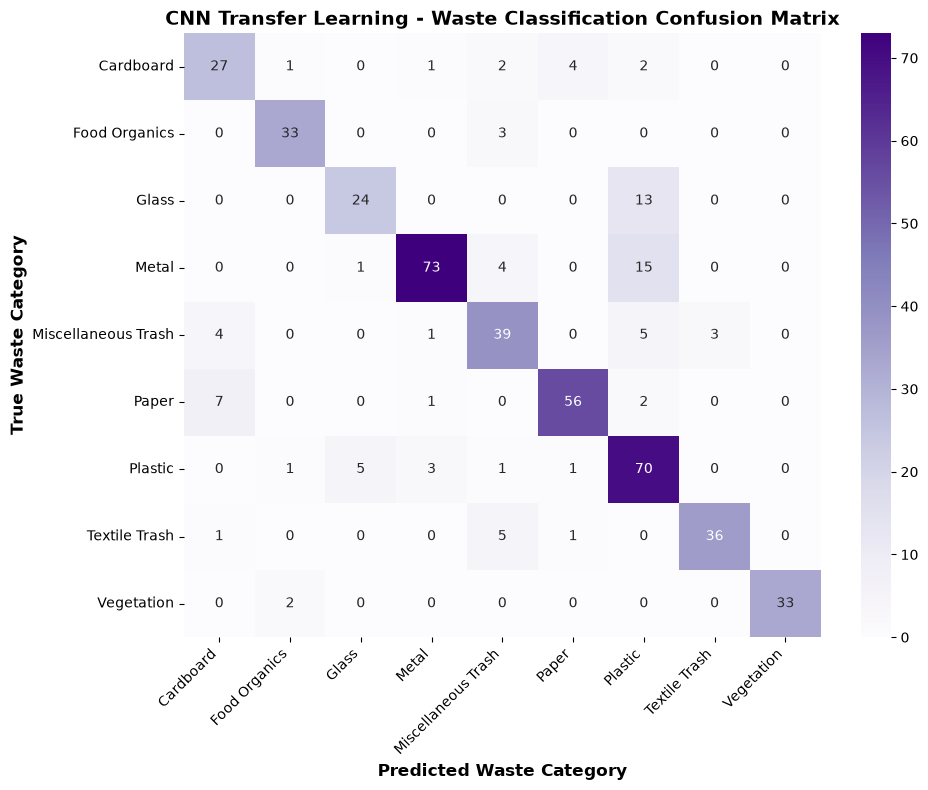


--- Detailed Classification Report ---
                     precision    recall  f1-score   support

          Cardboard       0.69      0.73      0.71        37
      Food Organics       0.89      0.92      0.90        36
              Glass       0.80      0.65      0.72        37
              Metal       0.92      0.78      0.85        93
Miscellaneous Trash       0.72      0.75      0.74        52
              Paper       0.90      0.85      0.88        66
            Plastic       0.65      0.86      0.74        81
      Textile Trash       0.92      0.84      0.88        43
         Vegetation       1.00      0.94      0.97        35

           accuracy                           0.81       480
          macro avg       0.83      0.81      0.82       480
       weighted avg       0.83      0.81      0.82       480



In [ ]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here
# 1. Test Set Evaluation: We evaluate our trained model on the unseen `test_processed`
#    dataset to measure objective generalization performance (Test Accuracy & Loss).
# 2. Prediction Generation: We extract true labels and generate predicted probabilities
#    across all test batches, converting one-hot encodings and probabilities into
#    discrete class indices using `argmax`.
# 3. Confusion Matrix & Classification Report: We compute a scikit-learn confusion matrix
#    and plot it using Seaborn/Matplotlib to visualize exactly which waste categories
#    the model confuses (e.g., Plastic vs. Miscellaneous Trash).

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Step A: Evaluate overall model performance on the test set
print("Evaluating model on test dataset...")
test_loss, test_accuracy = model.evaluate(test_processed)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%\n")

# Step B: Collect true labels and model predictions from test_processed
true_labels = []
predicted_labels = []

for images, labels in test_processed:
    # Get model predictions
    preds = model.predict(images, verbose=0)
    # Convert one-hot vectors back to integer class indices
    true_batch_labels = np.argmax(labels.numpy(), axis=1)
    pred_batch_labels = np.argmax(preds, axis=1)

    true_labels.extend(true_batch_labels)
    predicted_labels.extend(pred_batch_labels)

true_labels = np.array(true_labels)
predicted_labels = np.array(predicted_labels)

# Step C: Generate and plot the Confusion Matrix
conf_matrix = confusion_matrix(true_labels, predicted_labels)

plt.figure(figsize=(10, 8))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted Waste Category', fontsize=12, fontweight='bold')
plt.ylabel('True Waste Category', fontsize=12, fontweight='bold')
plt.title('CNN Transfer Learning - Waste Classification Confusion Matrix', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Step D: Print detailed classification report (Precision, Recall, F1-Score)
print("\n--- Detailed Classification Report ---")
print(classification_report(true_labels, predicted_labels, target_names=class_names))


### 2.4 Fine-tune the Model

In [ ]:
# TODO: Tune model parameters to improve performance
# - Adjust learning rate
# - Add regularization, dropout
# - Modify architecture if needed

# Your code here

# 1. Unfreezing Base Model Layers: To boost accuracy further, we unfreeze the
#    top layers of our MobileNetV2 base model (e.g., from layer 100 onwards) so that
#    they can fine-tune high-level domain-specific features specific to waste images.
# 2. Reduced Learning Rate: We recompile the model using a much smaller learning rate
#    (`1e-5`) with the Adam optimizer. This prevents catastrophic forgetting or
#    destructive gradient updates when tuning pre-trained weights.
# 3. Extended Training with Early Stopping: We train for additional epochs with
#    stricter patience monitoring to lock in peak performance without overfitting.


# Step A: Unfreeze the top layers of MobileNetV2 for fine-tuning
base_model.trainable = True

# Freeze all layers up to a specific layer index (e.g., fine-tune the last 30 layers)
fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print(f"Total layers in base model: {len(base_model.layers)}")
print(f"Fine-tuning from layer {fine_tune_at} onwards.")

# Step B: Recompile the model with a much smaller learning rate for delicate weight tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Step C: Define fine-tuning callbacks and continue training
fine_tune_epochs = 10
total_epochs = history.epoch[-1] + fine_tune_epochs + 1 if 'history' in locals() else 10

fine_tune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

print("Starting model fine-tuning...")
fine_tune_history = model.fit(
    train_processed,
    validation_data=validation_processed,
    epochs=total_epochs,
    initial_epoch=history.epoch[-1] + 1 if 'history' in locals() else 0,
    callbacks=[fine_tune_early_stopping]
)

print("CNN model fine-tuning successfully completed!")

Total layers in base model: 154
Fine-tuning from layer 124 onwards.
Starting model fine-tuning...
Epoch 11/20


/home/komen/Documents/moringa_school_projects/Module_5_labs/dsc-ecosort-nn-summative-lab/VENV/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 182s 1s/step - accuracy: 0.7751 - loss: 0.6502 - val_accuracy: 0.7936 - val_loss: 0.5809
Epoch 12/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step - accuracy: 0.8330 - loss: 0.4772 - val_accuracy: 0.7957 - val_loss: 0.5767
Epoch 13/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 153s 1s/step - accuracy: 0.8806 - loss: 0.3612 - val_accuracy: 0.7915 - val_loss: 0.5619
Epoch 14/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 159s 1s/step - accuracy: 0.9029 - loss: 0.3074 - val_accuracy: 0.8085 - val_loss: 0.5522
Epoch 15/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 168s 1s/step - accuracy: 0.9240 - loss: 0.2620 - val_accuracy: 0.8191 - val_loss: 0.5488
Epoch 16/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 165s 1s/step - accuracy: 0.9495 - loss: 0.2126 - val_accuracy: 0.8255 - val_loss: 0.5390
Epoch 17/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 162s 1s/step - accuracy: 0.9561 - loss: 0.1846 - val_accuracy: 0.8277 - val_loss: 0.5349
Epoch 18/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 161s 1s/step - accuracy: 0.9682 - loss: 0.1560 - val_accuracy

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [13]:
# TODO: Implement text preprocessing
# - Apply the text preprocessing pipeline created earlier

# Your code here

### 3.2 Implement Text Classification Model

In [14]:
# TODO: Choose and implement a text classification model
# Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
# Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)

# Your code here

### 3.3 Train and Evaluate the Model

In [15]:
# TODO: Train the text classification model
# - Use appropriate training parameters
# - Monitor training progress

# Your code here

In [16]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Your code here

### 3.4 Create Classification Function

In [17]:
# TODO: Create a function that takes a text description and returns the predicted waste category

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    # Your code here
    pass

## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [18]:
# TODO: Prepare documents for retrieval
# - Process policy documents and disposal instructions
# - Create embeddings for efficient retrieval

# Your code here

### 4.2 Implement RAG-based System

In [19]:
# TODO: Select a pre-trained language model and implement RAG
# - Choose an appropriate language model
# - Create a retrieval mechanism

# Your code here

### 4.3 Adjust and Evaluate the System

In [20]:
# TODO: Train the RAG-based system
# - Adjust sampling methods/parameters

# Your code here

In [21]:
# TODO: Evaluate the quality of generated instructions
# - Test with various waste categories
# - Assess relevance and accuracy

# Your code here

### 4.4 Create Instruction Generation Function

In [22]:
# TODO: Create a function that takes a waste category and generates recycling instructions

def generate_recycling_instructions(waste_category):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents
    """
    # Your code here
    pass

## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

In [23]:
# TODO: Design an architecture that integrates all three models
# - Create interfaces between components
# - Handle input/output flow

# Your code here

### 5.2 Implement Integrated Assistant

In [24]:
# TODO: Implement the integrated waste management assistant

def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions
    """
    # Your code here
    pass

### 5.3 Evaluate the Integrated System

In [25]:
# TODO: Evaluate the integrated system on test cases
# - Test with images from test dataset
# - Test with text descriptions from test dataset
# - Assess overall performance

# Your code here

## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.